# Wind Loads
**ASCE 7-22 Chapters 26, 27 (MWFRS directional procedure), and 30 (C&C walls) · IBC 2024**

Rectangular building with a flat, gable, or hip roof. Computes velocity pressures using the
ASCE 7-22 Kz constants, external pressure coefficients from Fig. 27.3-1, net design pressures
for both internal pressure signs, base shear and overturning in both principal directions
(including the 27.1.5 minimum), and C&C wall pressures for Zones 4 and 5.
Pressures are strength-level (load case W).

**How to use:** Run the **Engine** cell once, edit the form fields below, and run **Runtime → Run all** (`Ctrl+F9` / `⌘F9`). Get V for your Risk Category from the ASCE 7 Hazard Tool.

> Design aid only. A licensed engineer must verify all inputs and results.

In [1]:
#@title Engine — run this cell first (embedded structcalc library) { display-mode: "form" }
# Unpacks the embedded structcalc library and imports it (no pip install or Drive mount needed).
# Source: structural-calculations (lib/structcalc). Rebuild notebooks with: python build.py
import base64 as _b64, io as _io, os as _os, sys as _sys, tempfile as _tf, zipfile as _zf
_ZIP = (
    "..."
)
_dir = _os.path.join(_tf.gettempdir(), "structcalc_476d0793fd")
if not _os.path.isdir(_os.path.join(_dir, "structcalc")):
    _zf.ZipFile(_io.BytesIO(_b64.b64decode(_ZIP))).extractall(_dir)
for _m in [m for m in _sys.modules if m == "structcalc" or m.startswith("structcalc.")]:
    del _sys.modules[_m]
if _dir not in _sys.path:
    _sys.path.insert(0, _dir)
import structcalc
print(f"structcalc {structcalc.__version__} ready (build 476d0793fd)")

structcalc 0.1.0 ready (build 476d0793fd)


In [2]:
#@title 1. Site and wind parameters
V = 115.0  #@param {type:"number"}
risk_category = "II"  #@param ["I", "II", "III", "IV"]
exposure = "C"  #@param ["B", "C", "D"]
Kzt = 1.0  #@param {type:"number"}
ground_elevation_ft = 0.0  #@param {type:"number"}
use_Ke = True  #@param {type:"boolean"}
Kd = 0.85  #@param {type:"number"}
G = 0.85  #@param {type:"number"}
enclosure = "Enclosed"  #@param ["Enclosed", "Partially enclosed", "Partially open", "Open"]
#@markdown V in mph (3-second gust, Risk Category specific map). Kd = 0.85 for buildings. G = 0.85 for rigid buildings.

In [3]:
#@title 2. Building geometry (ft, degrees)
roof_type = "Gable"  #@param ["Flat", "Gable", "Hip"]
roof_angle = 20.0  #@param {type:"number"}
eave_height = 20.0  #@param {type:"number"}
B_along_ridge = 100.0  #@param {type:"number"}
L_across_ridge = 60.0  #@param {type:"number"}
heights = ""  #@param {type:"string"}
cc_effective_area = 20.0  #@param {type:"number"}
#@markdown *heights*: optional list of heights for the qz table, separated by `;` (blank = automatic).
#@markdown *cc_effective_area*: effective wind area of the wall component in ft².

In [4]:
#@title 3. Calculate
from structcalc.calcs import wind_loads

out = wind_loads.run(
    V=V, exposure=exposure, Kzt=Kzt, ground_elev=ground_elevation_ft, use_Ke=use_Ke,
    Kd=Kd, G=G, enclosure=enclosure, roof_type=roof_type, theta=roof_angle,
    h_eave=eave_height, B_ridge=B_along_ridge, L_across=L_across_ridge,
    heights=heights, cc_area=cc_effective_area, risk_category=risk_category,
)
out["report"].show()

Basic wind speed V Risk Category II,115,mph
Exposure,C,
Kzt,1,
Ground elevation,0,ft
Kd Table 26.6-1,0.85,
Gust effect factor G 26.11.1 rigid,0.85,
Enclosure,Enclosed,
Roof type,Gable,
Roof angle,20,deg
Eave height,20,ft
Plan dimension along ridge B,100,ft


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


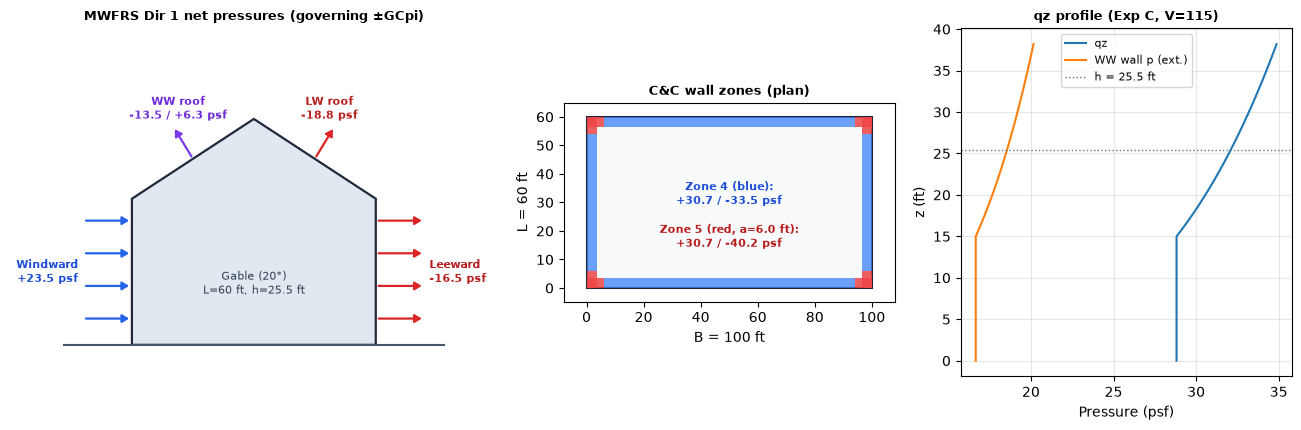

In [5]:
#@title 4. Wind pressures, C&C zones, and velocity pressure profile
fig = wind_loads.plot(out)

In [6]:
#@title 5. Save report as HTML (optional)
save_report = False  #@param {type:"boolean"}
if save_report:
    path = out["report"].save_html("wind_loads.html")
    print("saved", path)
    try:
        from google.colab import files
        files.download(path)
    except ImportError:
        pass